In [1]:
!pip -q install osmnx geopandas folium pandas matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 3.2 MB/s eta 0:00:00


In [2]:
import os
import json
import warnings
from datetime import datetime, timezone

import pandas as pd
import geopandas as gpd
import osmnx as ox
import folium
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)

# Konfigurasi proyek
NAMA_WILAYAH = "Kota Bengkulu, Bengkulu, Indonesia"
FOLDER = "/content/gis-fasilitas-kesehatan"
FOLDER_HASIL = os.path.join(FOLDER, "hasil")

os.makedirs(FOLDER_HASIL, exist_ok=True)

# Metadata sumber data
WAKTU_PENGAMBILAN = datetime.now(timezone.utc).strftime(
    "%Y-%m-%d %H:%M:%S UTC"
)

print("Proyek GIS siap.")
print("Wilayah:", NAMA_WILAYAH)
print("Waktu pengerjaan:", WAKTU_PENGAMBILAN)
print("Folder hasil:", FOLDER_HASIL)


Proyek GIS siap.
Wilayah: Kota Bengkulu, Bengkulu, Indonesia
Waktu pengerjaan: 2026-10-17 06:36:11 UTC
Folder hasil: /content/gis-fasilitas-kesehatan/hasil


In [3]:
# Sumber data geografis
SUMBER_DATA = "OpenStreetMap"
URL_SUMBER = "https://www.openstreetmap.org/"

# Kategori fasilitas yang dicari
TAGS_KESEHATAN = {
    "amenity": [
        "hospital",
        "clinic",
        "doctors",
        "dentist",
        "pharmacy"
    ]
}

print("Sumber:", SUMBER_DATA)
print("Kategori:", TAGS_KESEHATAN["amenity"])


Sumber: OpenStreetMap
Kategori: ['hospital', 'clinic', 'doctors', 'dentist', 'pharmacy']


In [4]:
batas_wilayah = ox.geocode_to_gdf(NAMA_WILAYAH)

if batas_wilayah.empty:
    raise ValueError(
        "Batas wilayah tidak ditemukan. Periksa nama wilayah "
        "atau coba kembali ketika koneksi tersedia."
    )

print("Batas wilayah berhasil diambil.")
display(batas_wilayah[["display_name"]])

# Simpan batas wilayah asli
file_batas = os.path.join(FOLDER_HASIL, "batas_wilayah.geojson")
batas_wilayah.to_file(file_batas, driver="GeoJSON")

print("Disimpan:", file_batas)


Batas wilayah berhasil diambil.


,display_name
0,"Bengkulu, Teluk Segara, Bengkulu, Indonesia"


Disimpan: /content/gis-fasilitas-kesehatan/hasil/batas_wilayah.geojson


In [5]:
print("Sedang mengambil data dari OpenStreetMap...")

fasilitas_asli = ox.features_from_place(
    NAMA_WILAYAH,
    tags=TAGS_KESEHATAN
)

if fasilitas_asli.empty:
    raise ValueError(
        "Tidak ada objek yang ditemukan. Periksa koneksi internet "
        "dan coba jalankan kembali cell ini."
    )

print("Pengambilan data selesai.")
print("Jumlah objek mentah:", len(fasilitas_asli))
print("Sistem koordinat awal:", fasilitas_asli.crs)

display(fasilitas_asli.head())


Sedang mengambil data dari OpenStreetMap...
Pengambilan data selesai.
Jumlah objek mentah: 27
Sistem koordinat awal: epsg:4326


geometry addr:city      addr:street  \
element id                                                                  
node    2441129247    POINT (102.27311 -3.801)  Bengkulu  Jalan S. Parman   
        2442226309  POINT (102.27496 -3.79429)       NaN              NaN   
        3130900961  POINT (102.28001 -3.76435)  Bengkulu     WR.Supratman   
        5343076775   POINT (102.3178 -3.89005)       NaN              NaN   
        5363287892  POINT (102.26686 -3.79825)       NaN              NaN   

                     amenity             name healthcare operator:type  \
element id                                                               
node    2441129247  pharmacy      Apotek Nita        NaN           NaN   
        2442226309  pharmacy  Apotek Keluarga        NaN           NaN   
        3130900961   doctors    dr.Lia Novita     doctor           NaN   
        5343076775  pharmacy      Apotik Kito        NaN           NaN   
        5363287892  pharmacy    Apotik Berkat        NaN       private   

                    source brand brand:wikidata  ... operator:wikidata  \
element id                                       ...                     
node    2441129247     NaN   NaN            NaN  ...               NaN   
        2442226309     NaN   NaN            NaN  ...               NaN   
        3130900961     NaN   NaN            NaN  ...               NaN   
        5343076775     NaN   NaN            NaN  ...               NaN   
        5363287892  survey   NaN            NaN  ...               NaN   

                   addr:full addr:postcode building:foundation  \
element id                                                       
node    2441129247       NaN           NaN                 NaN   
        2442226309       NaN           NaN                 NaN   
        3130900961       NaN           NaN                 NaN   
        5343076775       NaN           NaN                 NaN   
        5363287892       NaN           NaN                 NaN   

                   building:levels building:roof building:structure  \
element id                                                            
node    2441129247             NaN           NaN                NaN   
        2442226309             NaN           NaN                NaN   
        3130900961             NaN           NaN                NaN   
        5343076775             NaN           NaN                NaN   
        5363287892             NaN           NaN                NaN   

                   building:walls office website  
element id                                        
node    2441129247            NaN    NaN     NaN  
        2442226309            NaN    NaN     NaN  
        3130900961            NaN    NaN     NaN  
        5343076775            NaN    NaN     NaN  
        5363287892            NaN    NaN     NaN  

[5 rows x 30 columns]

In [6]:
print("Ukuran data mentah:", fasilitas_asli.shape)
print("\nKolom yang tersedia:")
print(fasilitas_asli.columns.tolist())

kolom_periksa = [
    kolom for kolom in
    ["name", "amenity", "healthcare", "operator"]
    if kolom in fasilitas_asli.columns
]

display(fasilitas_asli[kolom_periksa].head(10))

print("\nJumlah nilai kosong:")
display(fasilitas_asli[kolom_periksa].isna().sum())


Ukuran data mentah: (27, 30)

Kolom yang tersedia:
['geometry', 'addr:city', 'addr:street', 'amenity', 'name', 'healthcare', 'operator:type', 'source', 'brand', 'brand:wikidata', 'dispensing', 'emergency', 'healthcare:speciality', 'name:id', 'operator', 'phone', 'building', 'building:condition', 'operator:en', 'operator:id', 'operator:wikidata', 'addr:full', 'addr:postcode', 'building:foundation', 'building:levels', 'building:roof', 'building:structure', 'building:walls', 'office', 'website']


name   amenity healthcare operator
element id                                                          
node    2441129247         Apotek Nita  pharmacy        NaN      NaN
        2442226309     Apotek Keluarga  pharmacy        NaN      NaN
        3130900961       dr.Lia Novita   doctors     doctor      NaN
        5343076775         Apotik Kito  pharmacy        NaN      NaN
        5363287892       Apotik Berkat  pharmacy        NaN      NaN
        5367985797       Apotik Kompas  pharmacy        NaN      NaN
        5367985799           Puskesmas    clinic        NaN      NaN
        5368048248  Apotik Kimia Farma  pharmacy        NaN      NaN
        5368109557           Puskesmas    clinic        NaN      NaN
        5368125814         Apotik Nova  pharmacy        NaN      NaN


Jumlah nilai kosong:


,0
name,0
amenity,0
healthcare,15
operator,24


In [7]:
data = fasilitas_asli.copy()

# Buang objek tanpa geometri yang dapat digunakan
data = data[
    data.geometry.notna() & ~data.geometry.is_empty
].copy()

if data.crs is None:
    raise ValueError("CRS tidak tersedia; analisis spasial dihentikan.")

# Pertahankan kategori dari atribut sumber
if "amenity" not in data.columns:
    raise ValueError("Kolom amenity tidak tersedia pada data sumber.")

data["jenis"] = data["amenity"].astype("string")

# Pastikan hanya kategori yang diminta yang digunakan
kategori_valid = TAGS_KESEHATAN["amenity"]
data = data[data["jenis"].isin(kategori_valid)].copy()

# Nama yang tidak tercatat ditandai, bukan direkayasa
if "name" not in data.columns:
    data["name"] = pd.NA

data["nama_fasilitas"] = (
    data["name"].astype("string").fillna("Tidak tercatat")
)

# Simpan ID sumber agar setiap objek bisa ditelusuri
data = data.reset_index()

kolom_id = [c for c in ["element", "id"] if c in data.columns]
if kolom_id:
    data["osm_id"] = (
        data[kolom_id].astype(str).agg("/".join, axis=1)
    )
else:
    data["osm_id"] = data.index.astype(str)

print("Objek setelah pembersihan:", len(data))
display(data[["osm_id", "nama_fasilitas", "jenis"]].head(10))


Objek setelah pembersihan: 27


,osm_id,nama_fasilitas,jenis
0,node/2441129247,Apotek Nita,pharmacy
1,node/2442226309,Apotek Keluarga,pharmacy
2,node/3130900961,dr.Lia Novita,doctors
3,node/5343076775,Apotik Kito,pharmacy
4,node/5363287892,Apotik Berkat,pharmacy
5,node/5367985797,Apotik Kompas,pharmacy
6,node/5367985799,Puskesmas,clinic
7,node/5368048248,Apotik Kimia Farma,pharmacy
8,node/5368109557,Puskesmas,clinic
9,node/5368125814,Apotik Nova,pharmacy


In [8]:

# Proyeksi metrik untuk wilayah Bengkulu
data_meter = data.to_crs(epsg=32748).copy()

# Wakili tiap objek dengan satu titik di dalam geometrinya
data_meter["geometry"] = data_meter.geometry.representative_point()

# Ubah kembali ke lintang-bujur
data_peta = data_meter.to_crs(epsg=4326).copy()

dataset = pd.DataFrame({
    "osm_id": data_peta["osm_id"].astype(str),
    "nama_fasilitas": data_peta["nama_fasilitas"].astype(str),
    "jenis": data_peta["jenis"].astype(str),
    "latitude": data_peta.geometry.y,
    "longitude": data_peta.geometry.x
})

# Hapus hanya koordinat yang tidak valid
dataset = dataset.dropna(subset=["latitude", "longitude"])
dataset = dataset.drop_duplicates(subset=["osm_id"])

if len(dataset) == 0:
    raise ValueError("Dataset bersih kosong. Periksa data sumber.")

file_csv = os.path.join(FOLDER_HASIL, "fasilitas_kesehatan.csv")
dataset.to_csv(file_csv, index=False, encoding="utf-8-sig")

print("Jumlah data akhir:", len(dataset))
print("Dataset tersimpan:", file_csv)
display(dataset.head(10))


Jumlah data akhir: 27
Dataset tersimpan: /content/gis-fasilitas-kesehatan/hasil/fasilitas_kesehatan.csv


,osm_id,nama_fasilitas,jenis,latitude,longitude
0,node/2441129247,Apotek Nita,pharmacy,-3.800996,102.273114
1,node/2442226309,Apotek Keluarga,pharmacy,-3.794294,102.274965
2,node/3130900961,dr.Lia Novita,doctors,-3.764349,102.280010
3,node/5343076775,Apotik Kito,pharmacy,-3.890051,102.317803
4,node/5363287892,Apotik Berkat,pharmacy,-3.798249,102.266863
5,node/5367985797,Apotik Kompas,pharmacy,-3.801415,102.264183
6,node/5367985799,Puskesmas,clinic,-3.808556,102.266288
7,node/5368048248,Apotik Kimia Farma,pharmacy,-3.798332,102.267023
8,node/5368109557,Puskesmas,clinic,-3.801051,102.266503
9,node/5368125814,Apotik Nova,pharmacy,-3.807608,102.267316


Jumlah fasilitas berdasarkan jenis:


,jenis,jumlah
3,pharmacy,10
2,hospital,8
0,clinic,7
1,doctors,2


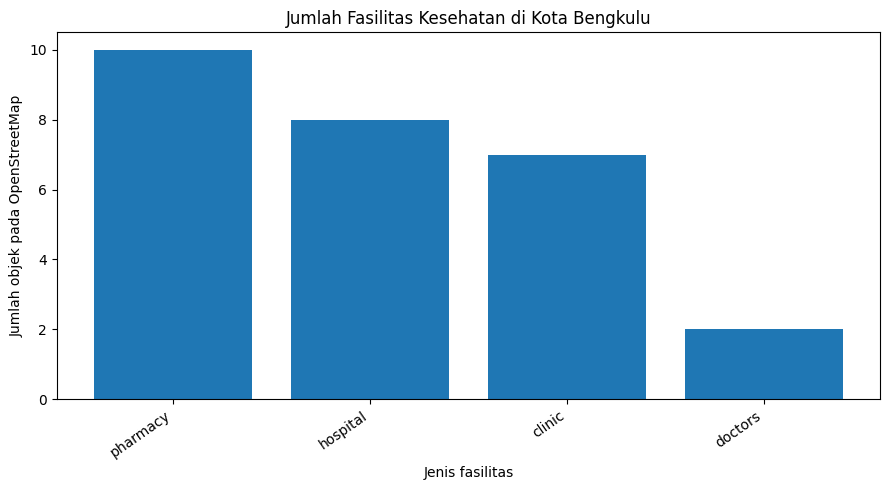

In [9]:

ringkasan = (
    dataset.groupby("jenis")
    .size()
    .reset_index(name="jumlah")
    .sort_values("jumlah", ascending=False)
)

file_ringkasan = os.path.join(
    FOLDER_HASIL, "ringkasan_fasilitas.csv"
)
ringkasan.to_csv(file_ringkasan, index=False)

print("Jumlah fasilitas berdasarkan jenis:")
display(ringkasan)

plt.figure(figsize=(9, 5))
plt.bar(ringkasan["jenis"], ringkasan["jumlah"])
plt.title("Jumlah Fasilitas Kesehatan di Kota Bengkulu")
plt.xlabel("Jenis fasilitas")
plt.ylabel("Jumlah objek pada OpenStreetMap")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

file_grafik = os.path.join(
    FOLDER_HASIL, "grafik_jumlah_fasilitas.png"
)
plt.savefig(file_grafik, dpi=160, bbox_inches="tight")
plt.show()


Statistik jarak ke fasilitas lain terdekat:
Rata-rata: 759.0 meter
Median: 261.02 meter


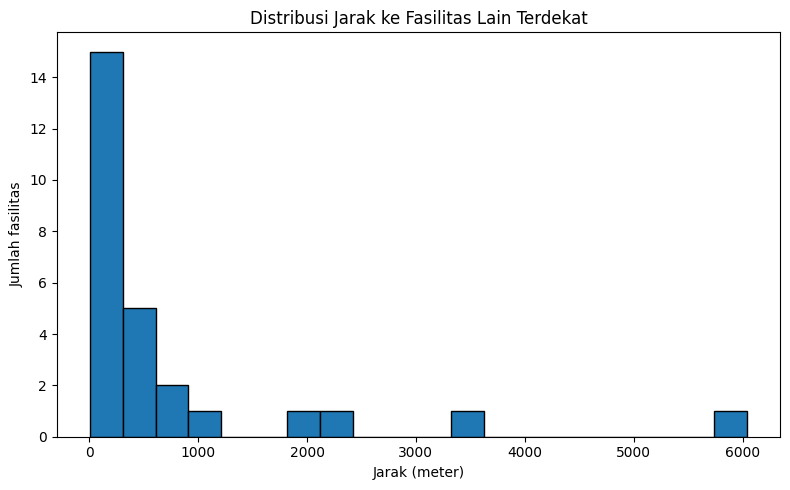

In [10]:

if len(dataset) >= 2:
    # Gunakan geometri proyeksi yang sesuai dengan baris dataset
    titik_meter = data_meter.loc[dataset.index].copy()

    koordinat_xy = pd.DataFrame({
        "x": titik_meter.geometry.x,
        "y": titik_meter.geometry.y
    }, index=dataset.index)

    # Cari 2 titik terdekat: titik itu sendiri dan tetangga terdekat
    model = NearestNeighbors(n_neighbors=2, metric="euclidean")
    model.fit(koordinat_xy[["x", "y"]])

    jarak, indeks = model.kneighbors(koordinat_xy[["x", "y"]])

    dataset["jarak_terdekat_meter"] = jarak[:, 1]

    print("Statistik jarak ke fasilitas lain terdekat:")
    print(
        "Rata-rata:",
        round(dataset["jarak_terdekat_meter"].mean(), 2),
        "meter"
    )
    print(
        "Median:",
        round(dataset["jarak_terdekat_meter"].median(), 2),
        "meter"
    )

    plt.figure(figsize=(8, 5))
    plt.hist(
        dataset["jarak_terdekat_meter"],
        bins=20,
        edgecolor="black"
    )
    plt.title("Distribusi Jarak ke Fasilitas Lain Terdekat")
    plt.xlabel("Jarak (meter)")
    plt.ylabel("Jumlah fasilitas")
    plt.tight_layout()

    file_jarak = os.path.join(
        FOLDER_HASIL, "grafik_jarak_terdekat.png"
    )
    plt.savefig(file_jarak, dpi=160, bbox_inches="tight")
    plt.show()

    # Perbarui CSV dengan hasil analisis jarak
    dataset.to_csv(file_csv, index=False, encoding="utf-8-sig")
else:
    print(
        "Analisis jarak memerlukan sedikitnya dua objek. "
        "Hasil jarak tidak dibuat karena data belum mencukupi."
    )


In [11]:

pusat_peta = [
    dataset["latitude"].mean(),
    dataset["longitude"].mean()
]

peta = folium.Map(
    location=pusat_peta,
    zoom_start=12,
    tiles="OpenStreetMap"
)

# Tambahkan batas wilayah
folium.GeoJson(
    batas_wilayah.to_crs(epsg=4326).__geo_interface__,
    name="Batas wilayah Kota Bengkulu",
    style_function=lambda feature: {
        "color": "blue",
        "weight": 2,
        "fillOpacity": 0.04
    }
).add_to(peta)

# Warna hanya untuk membedakan kategori pada tampilan
warna = {
    "hospital": "red",
    "clinic": "green",
    "doctors": "blue",
    "dentist": "purple",
    "pharmacy": "orange"
}

# Tambahkan titik dari koordinat dataset asli
for _, baris in dataset.iterrows():
    jenis = str(baris["jenis"])
    nama = str(baris["nama_fasilitas"])

    isi_popup = (
        f"<b>Nama:</b> {nama}<br>"
        f"<b>Jenis:</b> {jenis}<br>"
        f"<b>OSM ID:</b> {baris['osm_id']}"
    )

    folium.CircleMarker(
        location=[baris["latitude"], baris["longitude"]],
        radius=5,
        color=warna.get(jenis, "gray"),
        fill=True,
        fill_opacity=0.75,
        popup=folium.Popup(isi_popup, max_width=300),
        tooltip=f"{jenis}: {nama}"
    ).add_to(peta)

folium.LayerControl().add_to(peta)

file_peta = os.path.join(
    FOLDER_HASIL, "peta_fasilitas_kesehatan.html"
)
peta.save(file_peta)

print("Peta tersimpan:", file_peta)
display(peta)


Peta tersimpan: /content/gis-fasilitas-kesehatan/hasil/peta_fasilitas_kesehatan.html


In [12]:

print("=" * 55)
print("HASIL ANALISIS GIS FASILITAS KESEHATAN")
print("=" * 55)
print("Wilayah:", NAMA_WILAYAH)
print("Sumber data:", SUMBER_DATA)
print("Waktu pengambilan:", WAKTU_PENGAMBILAN)
print("Jumlah objek dalam dataset akhir:", len(dataset))
print("Jumlah kategori:", dataset["jenis"].nunique())

print("\nJumlah objek per jenis:")
display(ringkasan)

if "jarak_terdekat_meter" in dataset.columns:
    print(
        "\nRata-rata jarak ke tetangga terdekat:",
        round(dataset["jarak_terdekat_meter"].mean(), 2),
        "meter"
    )

print("\nBerkas hasil:")
for nama in sorted(os.listdir(FOLDER_HASIL)):
    print("-", nama)


HASIL ANALISIS GIS FASILITAS KESEHATAN
Wilayah: Kota Bengkulu, Bengkulu, Indonesia
Sumber data: OpenStreetMap
Waktu pengambilan: 2026-10-17 06:36:11 UTC
Jumlah objek dalam dataset akhir: 27
Jumlah kategori: 4

Jumlah objek per jenis:


,jenis,jumlah
3,pharmacy,10
2,hospital,8
0,clinic,7
1,doctors,2



Rata-rata jarak ke tetangga terdekat: 759.0 meter

Berkas hasil:
- batas_wilayah.geojson
- fasilitas_kesehatan.csv
- grafik_jarak_terdekat.png
- grafik_jumlah_fasilitas.png
- peta_fasilitas_kesehatan.html
- ringkasan_fasilitas.csv


In [13]:

for root, dirs, files_list in os.walk(FOLDER):
    level = root.replace(FOLDER, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for nama in sorted(files_list):
        path = os.path.join(root, nama)
        ukuran_kb = os.path.getsize(path) / 1024
        print(f"{indent}  {nama} ({ukuran_kb:.1f} KB)")


gis-fasilitas-kesehatan/
  hasil/
    batas_wilayah.geojson (42.2 KB)
    fasilitas_kesehatan.csv (2.6 KB)
    grafik_jarak_terdekat.png (30.5 KB)
    grafik_jumlah_fasilitas.png (46.3 KB)
    peta_fasilitas_kesehatan.html (80.1 KB)
    ringkasan_fasilitas.csv (0.1 KB)


In [15]:

import shutil
from google.colab import files

file_zip = shutil.make_archive(
    "/content/hasil_proyek",
    "zip",
    root_dir="/content/gis-fasilitas-kesehatan",
    base_dir="hasil"
)

print("ZIP berhasil dibuat:", file_zip)
files.download(file_zip)


ZIP berhasil dibuat: /content/hasil_proyek.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>